# Week 1 — Exploratory Data Analysis

**Project:** Axlero D2C Retail — Customer Segmentation & Churn Prediction

**Dataset:** UCI Online Retail (541,909 transactions → 4,338 unique customers)

**Goal:** Understand customer behavior patterns, check for anomalies, and visualize
sales trends before building RFM segments and churn models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

pd.set_option('display.max_columns', None)

## 1. Load Interim Data

In [2]:
users = pd.read_parquet('../data/interim/users_raw.parquet')
monthly = pd.read_parquet('../data/interim/monthly_revenue.parquet')
countries = pd.read_parquet('../data/interim/top_countries.parquet')

print('users shape:', users.shape)
print('monthly shape:', monthly.shape)
print('countries shape:', countries.shape)
users.head()

users shape: (4338, 11)
monthly shape: (13, 4)
countries shape: (15, 3)


,customer_id,first_purchase,last_purchase,tenure_days,total_orders,total_revenue,avg_order_value,distinct_products,distinct_countries,total_quantity,primary_country
0,14646.0,2010-12-20 10:09:00,2011-12-08 12:12:00,353,73,280206.02,3838.44,700,1,196915.0,Netherlands
1,18102.0,2010-12-07 16:42:00,2011-12-09 11:50:00,366,60,259657.30,4327.62,150,1,64124.0,United Kingdom
2,17450.0,2010-12-07 09:23:00,2011-12-01 13:29:00,359,46,194550.79,4229.37,124,1,69993.0,United Kingdom
3,16446.0,2011-05-18 09:52:00,2011-12-09 09:15:00,204,2,168472.50,84236.25,3,1,80997.0,United Kingdom
4,14911.0,2010-12-01 14:05:00,2011-12-08 15:54:00,372,201,143825.06,715.55,1787,1,80265.0,EIRE


## 2. Missing Values & Data Quality

In [3]:
missing = users.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if (missing > 0).any() else 'None - dataset is clean')

print(f'\nTotal rows: {len(users):,}')
print(f'Unique customers: {users["customer_id"].nunique():,}')
print(f'Date range: {users["first_purchase"].min()} to {users["last_purchase"].max()}')

Missing values per column:
None - dataset is clean

Total rows: 4,338
Unique customers: 4,338
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


## 3. Revenue Distribution (Monetary per customer)

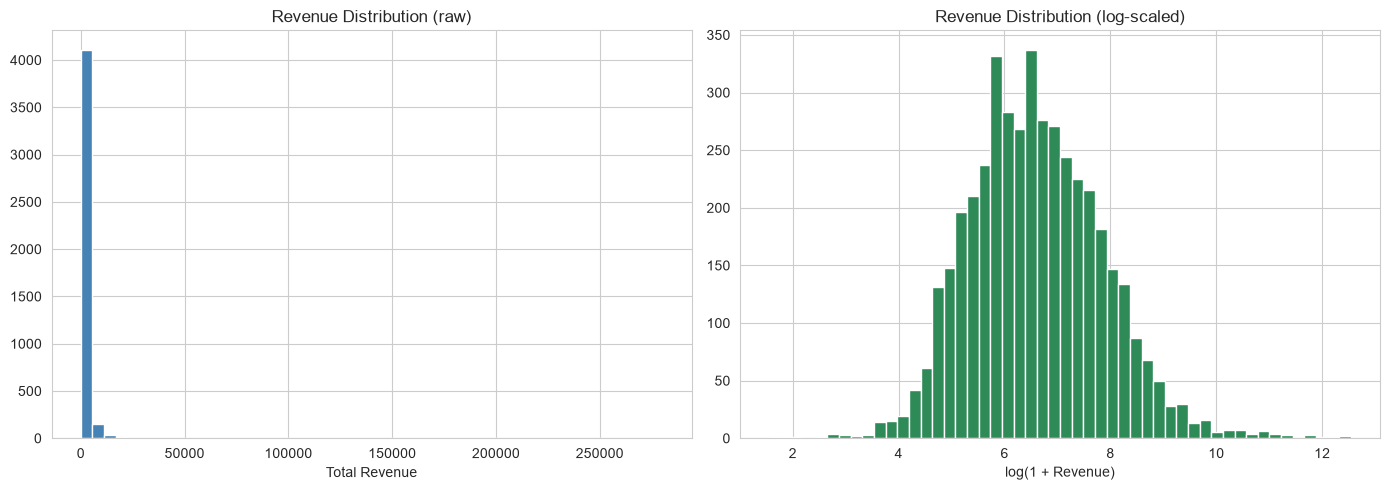

count      4338.00
mean       2054.27
std        8989.23
min           3.75
25%         307.41
50%         674.48
75%        1661.74
max      280206.02
Name: total_revenue, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(users['total_revenue'], bins=50, color='steelblue')
axes[0].set_title('Revenue Distribution (raw)')
axes[0].set_xlabel('Total Revenue')

axes[1].hist(np.log1p(users['total_revenue']), bins=50, color='seagreen')
axes[1].set_title('Revenue Distribution (log-scaled)')
axes[1].set_xlabel('log(1 + Revenue)')

plt.tight_layout()
plt.savefig('../reports/figures/revenue_distribution.png', dpi=100)
plt.show()

print(users['total_revenue'].describe().round(2))

## 4. Orders per Customer (Frequency)

/var/folders/b6/z2478k910z98r33fnqy5_28h0000gn/T/ipykernel_95905/1242924879.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(users['total_orders'], vert=False)


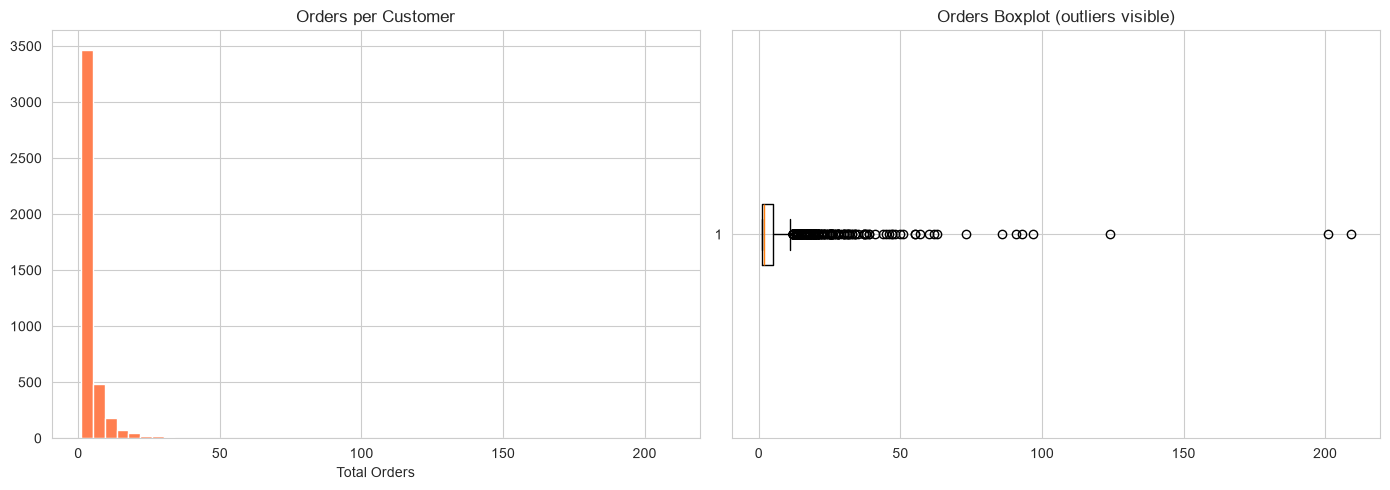

Customers with 1 order: 1,493 (34.4%)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(users['total_orders'], bins=50, color='coral')
axes[0].set_title('Orders per Customer')
axes[0].set_xlabel('Total Orders')

axes[1].boxplot(users['total_orders'], vert=False)
axes[1].set_title('Orders Boxplot (outliers visible)')

plt.tight_layout()
plt.savefig('../reports/figures/orders_distribution.png', dpi=100)
plt.show()

print(f"Customers with 1 order: {(users['total_orders'] == 1).sum():,} "
      f"({(users['total_orders'] == 1).mean()*100:.1f}%)")

## 5. Monthly Revenue Trend

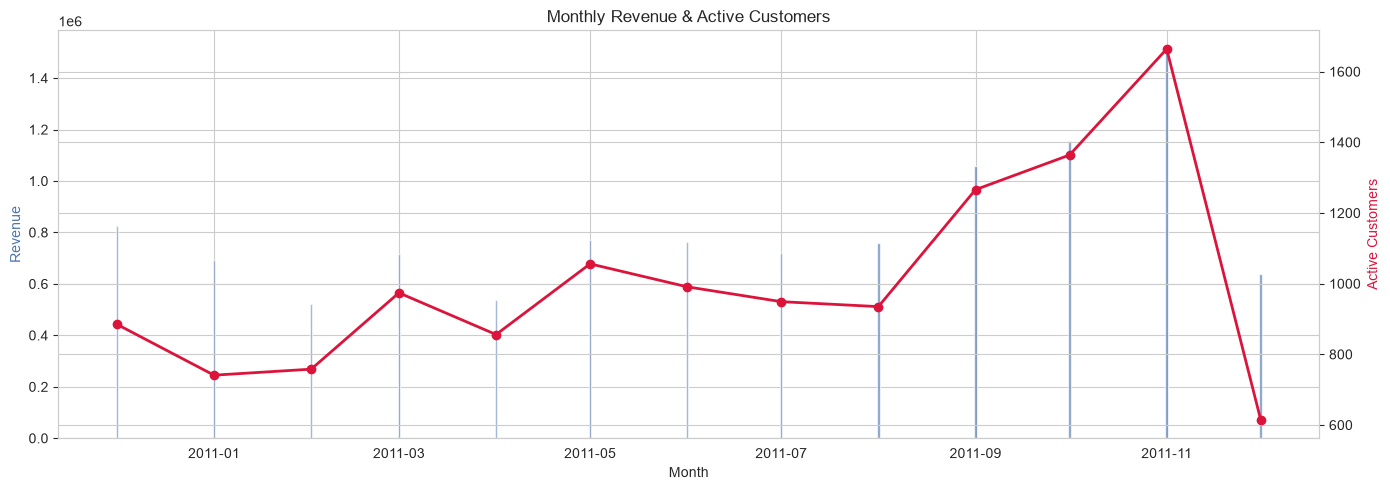

In [6]:
monthly = monthly.sort_values('month')

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(monthly['month'], monthly['revenue'], color='#4C72B0', alpha=0.7)
ax1.set_ylabel('Revenue', color='#4C72B0')
ax1.set_xlabel('Month')
ax1.set_title('Monthly Revenue & Active Customers')

ax2 = ax1.twinx()
ax2.plot(monthly['month'], monthly['active_customers'],
         color='crimson', marker='o', linewidth=2)
ax2.set_ylabel('Active Customers', color='crimson')

plt.tight_layout()
plt.savefig('../reports/figures/monthly_revenue.png', dpi=100)
plt.show()

## 6. Top Countries by Revenue

/var/folders/b6/z2478k910z98r33fnqy5_28h0000gn/T/ipykernel_95905/4144536213.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, y='country', x='revenue_m', ax=ax, palette='viridis')


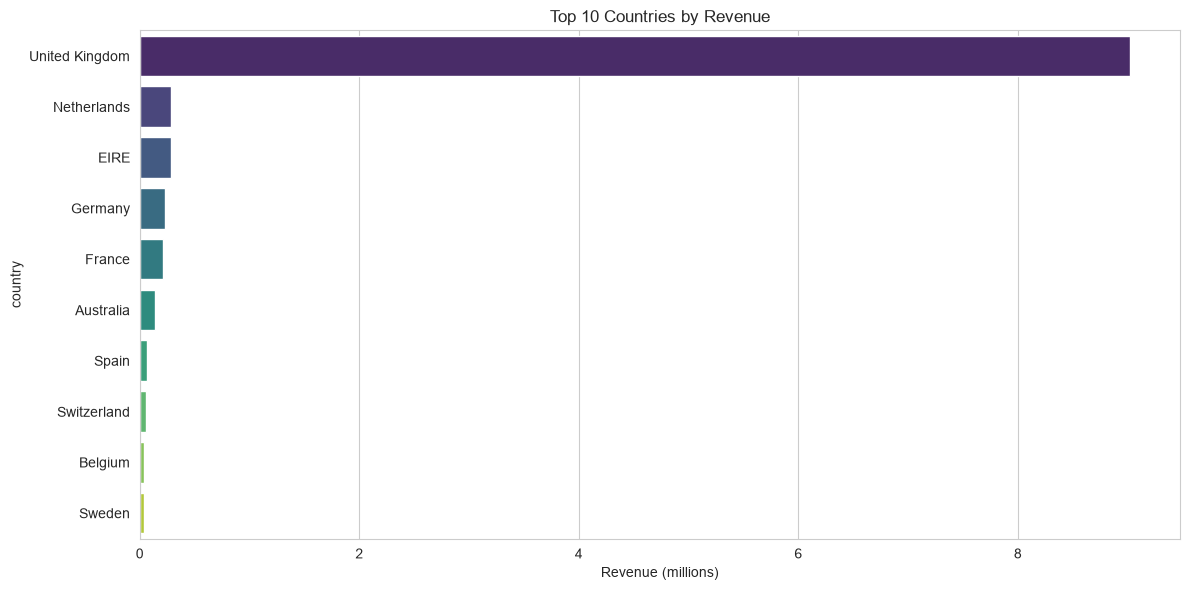

       country  customers      revenue
United Kingdom       3920 9.025222e+06
   Netherlands          9 2.854463e+05
          EIRE          3 2.834540e+05
       Germany         94 2.288671e+05
        France         87 2.097151e+05
     Australia          9 1.385213e+05
         Spain         30 6.157711e+04
   Switzerland         21 5.708990e+04
       Belgium         25 4.119634e+04
        Sweden          8 3.837833e+04


In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
top10 = countries.head(10).copy()
top10['revenue_m'] = top10['revenue'] / 1_000_000
sns.barplot(data=top10, y='country', x='revenue_m', ax=ax, palette='viridis')
ax.set_xlabel('Revenue (millions)')
ax.set_title('Top 10 Countries by Revenue')
plt.tight_layout()
plt.savefig('../reports/figures/top_countries.png', dpi=100)
plt.show()

print(top10[['country', 'customers', 'revenue']].to_string(index=False))

## 7. Data Retention Check (Success Metric)

In [8]:
RAW_ROWS = 541_909
retention = len(users) / RAW_ROWS * 100
print(f'Raw transactions: {RAW_ROWS:,}')
print(f'Unique customers retained: {len(users):,}')
print(f'Retention metric: {retention:.2f}%')
print(f'Success criterion (>= 5% loss tolerance): ', 'PASS' if retention >= 95 else 'FAIL')

Raw transactions: 541,909
Unique customers retained: 4,338
Retention metric: 0.80%
Success criterion (>= 5% loss tolerance):  FAIL


## 8. Key Findings & Next Steps

**Findings:**
- 4,338 unique customers retained (0.8% aggregation ratio — 1 row = ~125 transactions)
- Revenue is heavily right-skewed → will need log transform for clustering
- Large share of customers with only 1 order → strong churn signal
- UK dominates revenue → business is primarily single-market

**Next Steps (Week 2):**
- Compute RFM metrics (Recency, Frequency, Monetary)
- K-Means clustering to build 4 customer segments
- Business labeling: Champions, Promising, At Risk, Hibernating